# Milestone 2 · Features and baselines
**AIE231 Neural Networks · Course project** · Dataset: *Beijing Multi-Site Air Quality* (UCI #501)

**Goal of this notebook.** Turn the clean table from notebook 2 into model inputs (encoding, scaling fitted on train only, 24-hour windows) and set the bar the neural networks must beat with **two baselines**.

**Before running:** run `milestone2_Cleaning_Splits.ipynb` once, so `data/interim/clean.csv` and `configs/split.json` exist.

| § | Section | Function(s) |
|---|---|---|
| 0 | Setup and load | `load_clean()`, `time_split()` |
| 1 | Encoding (no fitting) | `encode_features()` |
| 2 | Scaling (fit on train only) | `fit_scalers()`, `apply_scalers()` |
| 3 | Windows (24 h in, PM2.5 at +6 h out) | `make_windows()`, `get_X()` |
| 4 | Metrics | `regression_metrics()` |
| 5 | Baseline 1: persistence | `persistence_baseline()` |
| 6 | Baseline 2: linear regression | `lag_features()`, `linear_baseline()` |
| 7 | Results and the bar to beat | `log_results()` |

## 0. Setup and load
### 0.1 Libraries and settings
`LOOKBACK` = how many past hours the model sees. `HORIZON` = how far ahead it predicts. Both are set once here.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score
import warnings
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)  # the 12 station columns always sum to 1; Ridge handles it

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

CLEAN_PATH = Path("data/interim/clean.csv")
SPLIT_PATH = Path("configs/split.json")
MODELS_DIR = Path("models")
RESULTS_PATH = Path("results/experiments.csv")

POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
TARGET = "PM2.5"

LOOKBACK = 24   # hours of history in one window
HORIZON = 6     # predict PM2.5 this many hours after the last hour of the window

EPA_BANDS = [0, 12, 35.4, 55.4, 150.4, 250.4, np.inf]
EPA_LABELS = ["Good", "Moderate", "Sensitive groups", "Unhealthy", "Very unhealthy", "Hazardous"]

### 0.2 Load the clean table and split it
Same split dates as notebook 2, read from `configs/split.json`, so both notebooks always agree.

In [2]:
def load_clean(clean_path=CLEAN_PATH, split_path=SPLIT_PATH):
    """Read the clean table from notebook 2 and the split dates."""
    df = pd.read_csv(clean_path, parse_dates=["datetime"])
    split = json.loads(Path(split_path).read_text())
    return df, pd.Timestamp(split["train_end"]), pd.Timestamp(split["val_end"])


def time_split(df, train_end, val_end):
    """Split by time, never shuffled: train <= train_end < val <= val_end < test."""
    train = df[df["datetime"] <= train_end]
    val = df[(df["datetime"] > train_end) & (df["datetime"] <= val_end)]
    test = df[df["datetime"] > val_end]
    return train.copy(), val.copy(), test.copy()


df_clean, TRAIN_END, VAL_END = load_clean()
print(df_clean.shape, "| train ends", TRAIN_END, "| validation ends", VAL_END)
df_clean.head(3)

(420768, 19) | train ends 2016-02-29 23:00:00 | validation ends 2016-08-31 23:00:00


,datetime,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,pm25_was_missing
0,2013-03-01 00:00:00,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,False
1,2013-03-01 01:00:00,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,False
2,2013-03-01 02:00:00,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,False


## 1. Encoding (no fitting)
Neural networks only take numbers, and they work best when "close" things look close. Nothing in this step learns from the data, so it is safe to apply to the whole table before splitting.

| Raw column | Becomes | Why |
|---|---|---|
| `hour`, `month` | sin/cos pairs | 23:00 sits next to 00:00, December next to January |
| `wd` (16 directions as text) | `wd_sin`, `wd_cos` | N sits next to NNW; 2 columns instead of 16 |
| `WSPM` + `wd` | `wind_u`, `wind_v` | strong NW wind cleans the air (EDA §7); speed and direction in one signal |
| `RAIN` (96% zeros) | `is_raining` 0/1 | no transform fixes a column that is almost always 0 |
| `TEMP`, `DEWP` | `RH` (relative humidity) | humid, still air traps smog |
| date | `cny` 0/1 | Chinese New Year fireworks caused the 999 spike (EDA §9) |
| `station` | 12 one-hot columns | one model serves all stations |
| `year`, `day` | dropped | the model should learn patterns, not calendar years |

In [3]:
WIND_ANGLE = {d: i * 22.5 for i, d in enumerate(
    ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"])}

# Chinese New Year eve to the second day of the new year (fireworks)
CNY_DAYS = pd.to_datetime([
    "2014-01-30", "2014-01-31", "2014-02-01", "2014-02-02",
    "2015-02-18", "2015-02-19", "2015-02-20", "2015-02-21",
    "2016-02-07", "2016-02-08", "2016-02-09", "2016-02-10",
    "2017-01-27", "2017-01-28", "2017-01-29", "2017-01-30",
])


def encode_features(df):
    """Turn the clean table into numeric model inputs. Learns nothing from the data."""
    out = df[["station", "datetime"]].copy()
    for col in POLLUTANTS + ["TEMP", "PRES", "DEWP", "WSPM"]:
        out[col] = df[col]

    hour, month = df["datetime"].dt.hour, df["datetime"].dt.month
    out["hour_sin"], out["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    out["month_sin"], out["month_cos"] = np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)

    angle = np.deg2rad(df["wd"].map(WIND_ANGLE))
    out["wd_sin"], out["wd_cos"] = np.sin(angle), np.cos(angle)
    out["wind_u"], out["wind_v"] = df["WSPM"] * np.sin(angle), df["WSPM"] * np.cos(angle)

    out["is_raining"] = (df["RAIN"] > 0).astype(float).where(df["RAIN"].notna())
    a, b = 17.625, 243.04   # Magnus formula for relative humidity (%)
    out["RH"] = (100 * np.exp(a * df["DEWP"] / (b + df["DEWP"])) / np.exp(a * df["TEMP"] / (b + df["TEMP"]))).clip(upper=100)
    out["cny"] = df["datetime"].dt.normalize().isin(CNY_DAYS).astype(float)

    stations = pd.get_dummies(df["station"], prefix="st", dtype=float)
    out = pd.concat([out, stations], axis=1)
    out["pm25_was_missing"] = df["pm25_was_missing"].astype(float)
    return out


encoded = encode_features(df_clean)
FEATURES = [c for c in encoded.columns if c not in ("station", "datetime")]
print(len(FEATURES), "input features:", FEATURES)
encoded.head(3)

34 input features: ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'WSPM', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'wd_sin', 'wd_cos', 'wind_u', 'wind_v', 'is_raining', 'RH', 'cny', 'st_Aotizhongxin', 'st_Changping', 'st_Dingling', 'st_Dongsi', 'st_Guanyuan', 'st_Gucheng', 'st_Huairou', 'st_Nongzhanguan', 'st_Shunyi', 'st_Tiantan', 'st_Wanliu', 'st_Wanshouxigong', 'pm25_was_missing']


,station,datetime,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,WSPM,hour_sin,hour_cos,month_sin,month_cos,wd_sin,wd_cos,wind_u,wind_v,is_raining,RH,cny,st_Aotizhongxin,st_Changping,st_Dingling,st_Dongsi,st_Guanyuan,st_Gucheng,st_Huairou,st_Nongzhanguan,st_Shunyi,st_Tiantan,st_Wanliu,st_Wanshouxigong,pm25_was_missing
0,Aotizhongxin,2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,4.4,0.000000,1.000000,1.0,6.123234e-17,-0.382683,0.92388,-1.683807,4.065070,0.0,24.008842,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,4.7,0.258819,0.965926,1.0,6.123234e-17,0.000000,1.00000,0.000000,4.700000,0.0,26.013678,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,5.6,0.500000,0.866025,1.0,6.123234e-17,-0.382683,0.92388,-2.143027,5.173725,0.0,26.013678,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**What we see.** 34 numeric inputs per hour. Two sanity checks: the wind vector is near zero when the air is still, and the CNY flag is on for 16 days × 24 hours × 12 stations.

In [4]:
print("CNY hours flagged:", int(encoded["cny"].sum()), "(expected 16 x 24 x 12 =", 16 * 24 * 12, ")")
print("RH range: %.0f%% to %.0f%%" % (encoded["RH"].min(), encoded["RH"].max()))

CNY hours flagged: 4608 (expected 16 x 24 x 12 = 4608 )
RH range: 2% to 100%


## 2. Scaling (fit on train only)
Scaling **learns numbers from the data** (Yeo-Johnson learns λ, the scaler learns a mean and a std). So we split first, fit on **train only**, and only *apply* the fitted transformers to validation and test (notebook 2, §6.3).

- **Yeo-Johnson** (also standardizes): the skewed columns PM2.5, PM10, SO2, NO2, CO, O3, WSPM.
- **StandardScaler:** TEMP, PRES, DEWP, RH, wind_u, wind_v.
- **A separate Yeo-Johnson for the target**, so predictions can be turned back into µg/m³ before scoring.
- sin/cos, 0/1 flags and one-hot columns are already on a small scale and stay as they are.

In [5]:
SKEWED = POLLUTANTS + ["WSPM"]
NORMAL = ["TEMP", "PRES", "DEWP", "RH", "wind_u", "wind_v"]


def fit_scalers(train_encoded):
    """Fit every transformer on the training split only."""
    return {
        "skewed": PowerTransformer(method="yeo-johnson").fit(train_encoded[SKEWED]),
        "normal": StandardScaler().fit(train_encoded[NORMAL]),
        "target": PowerTransformer(method="yeo-johnson").fit(train_encoded[[TARGET]].to_numpy()),
    }


def apply_scalers(encoded_df, scalers):
    """Apply already-fitted transformers. Missing values stay missing."""
    out = encoded_df.copy()
    out[SKEWED] = scalers["skewed"].transform(encoded_df[SKEWED])
    out[NORMAL] = scalers["normal"].transform(encoded_df[NORMAL])
    return out


enc_train, enc_val, enc_test = time_split(encoded, TRAIN_END, VAL_END)
scalers = fit_scalers(enc_train)
sc_train, sc_val, sc_test = (apply_scalers(d, scalers) for d in (enc_train, enc_val, enc_test))

MODELS_DIR.mkdir(exist_ok=True)
joblib.dump({"scalers": scalers, "features": FEATURES, "lookback": LOOKBACK, "horizon": HORIZON},
            MODELS_DIR / "preprocessor.joblib")
print("saved", MODELS_DIR / "preprocessor.joblib")

saved models/preprocessor.joblib


In [6]:
check = pd.DataFrame({
    "skew before (train)": enc_train[SKEWED + NORMAL].skew(),
    "skew after (train)": sc_train[SKEWED + NORMAL].skew(),
    "mean after (train)": sc_train[SKEWED + NORMAL].mean(),
    "std after (train)": sc_train[SKEWED + NORMAL].std(),
    "mean after (test)": sc_test[SKEWED + NORMAL].mean(),
}).round(2)
check

,skew before (train),skew after (train),mean after (train),std after (train),mean after (test)
PM2.5,1.96,-0.04,-0.0,1.0,0.04
PM10,1.82,-0.05,-0.0,1.0,-0.00
SO2,2.77,0.09,-0.0,1.0,-0.22
NO2,1.02,-0.05,-0.0,1.0,0.19
CO,2.42,-0.00,0.0,1.0,0.16
O3,1.48,-0.12,0.0,1.0,-0.48
WSPM,1.67,-0.00,0.0,1.0,-0.00
TEMP,-0.11,-0.11,-0.0,1.0,-0.58
PRES,0.09,0.09,0.0,1.0,0.70
DEWP,-0.21,-0.21,0.0,1.0,-0.41


**What we see.** On train, every scaled column has mean 0 and std 1, and the skew of the pollutants drops close to 0. On test the means are *not* exactly 0 (test is a smoggy winter). That is correct: it shows the test period stayed unseen when we fitted.

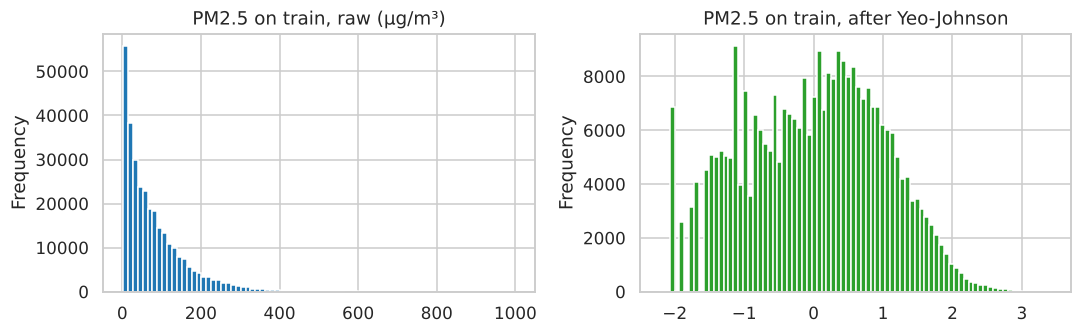

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
enc_train[TARGET].plot.hist(bins=80, ax=axes[0], color="tab:blue")
axes[0].set(title="PM2.5 on train, raw (µg/m³)", xlabel="")
sc_train[TARGET].plot.hist(bins=80, ax=axes[1], color="tab:green")
axes[1].set(title="PM2.5 on train, after Yeo-Johnson", xlabel="")
plt.tight_layout(); plt.show()

## 3. Windows: 24 hours in, PM2.5 6 hours later out
A recurrent network reads a **sequence**. One training example = the last `LOOKBACK` = 24 hours of all 34 inputs at one station, and the answer is PM2.5 `HORIZON` = 6 hours after the last of those hours.

Rules for a window to be kept:
1. All 24 hours come from **one station** and **one split** (built per split, so no window crosses a boundary, notebook 2 §6.4).
2. None of the 24 hours has a missing input.
3. The target hour exists and was **really measured** (`pm25_was_missing` is False). We never score the model on a value we filled in ourselves.

**Memory.** Stored as a full 3-D array, train would take about 1 GB. Instead `make_windows()` keeps the hourly table once and remembers *where* each window ends; `get_X()` builds the 3-D array only for the rows we ask for (a batch, a split, a plot).

In [8]:
def make_windows(scaled_split, raw_split, lookback=LOOKBACK, horizon=HORIZON):
    """Find every valid window in one split. Returns a dict of arrays (no 3-D copy)."""
    s = scaled_split.sort_values(["station", "datetime"]).reset_index(drop=True)
    r = raw_split.sort_values(["station", "datetime"]).reset_index(drop=True)
    values = s[FEATURES].to_numpy(dtype=np.float32)

    complete = ~np.isnan(values).any(axis=1)
    pos = s.groupby("station").cumcount().to_numpy()            # hour number inside its station
    n_station = s.groupby("station")["station"].transform("size").to_numpy()
    full_history = pd.Series(complete).groupby(s["station"]).transform(
        lambda x: x.rolling(lookback).sum()).to_numpy() == lookback

    target_raw = r.groupby("station")[TARGET].shift(-horizon).to_numpy()
    target_real = ~r.groupby("station")["pm25_was_missing"].shift(-horizon).fillna(True).astype(bool).to_numpy()

    ok = (pos >= lookback - 1) & (pos + horizon < n_station) & full_history \
         & ~np.isnan(target_raw) & target_real
    ends = np.flatnonzero(ok)
    return {
        "values": values,                                   # (hours, features), scaled
        "ends": ends,                                       # row of the last hour of each window
        "y": target_raw[ends],                              # PM2.5 at +6 h, µg/m³
        "y_scaled": scalers["target"].transform(target_raw[ends].reshape(-1, 1)).ravel(),
        "pm25_now": r[TARGET].to_numpy()[ends],             # PM2.5 at the last hour, µg/m³
        "station": s["station"].to_numpy()[ends],
        "time": s["datetime"].to_numpy()[ends],
        "hours": len(s),
    }


def get_X(win, idx=None, lookback=LOOKBACK):
    """Build the 3-D input (windows, lookback, features) for the chosen windows only."""
    ends = win["ends"] if idx is None else win["ends"][idx]
    offsets = np.arange(-lookback + 1, 1)
    return win["values"][ends[:, None] + offsets]


raw_train, raw_val, raw_test = time_split(df_clean, TRAIN_END, VAL_END)
win = {
    "train": make_windows(sc_train, raw_train),
    "validation": make_windows(sc_val, raw_val),
    "test": make_windows(sc_test, raw_test),
}
pd.DataFrame({name: {"hours": w["hours"], "windows": len(w["ends"]),
                     "kept %": round(100 * len(w["ends"]) / w["hours"], 1)}
              for name, w in win.items()}).T

,hours,windows,kept %
train,315648.0,242405.0,76.8
validation,52992.0,47543.0,89.7
test,52128.0,46223.0,88.7


In [9]:
X_val = get_X(win["validation"])
print("X_val:", X_val.shape, "= (windows, hours, features) | y_val:", win["validation"]["y"].shape)
print("one window in memory: %.1f KB | all train windows as 3-D: %.2f GB (so we build them in batches)"
      % (X_val[0].nbytes / 1024, len(win["train"]["ends"]) * X_val[0].nbytes / 1e9))

X_val: (47543, 24, 34) = (windows, hours, features) | y_val: (47543,)
one window in memory: 3.2 KB | all train windows as 3-D: 0.79 GB (so we build them in batches)


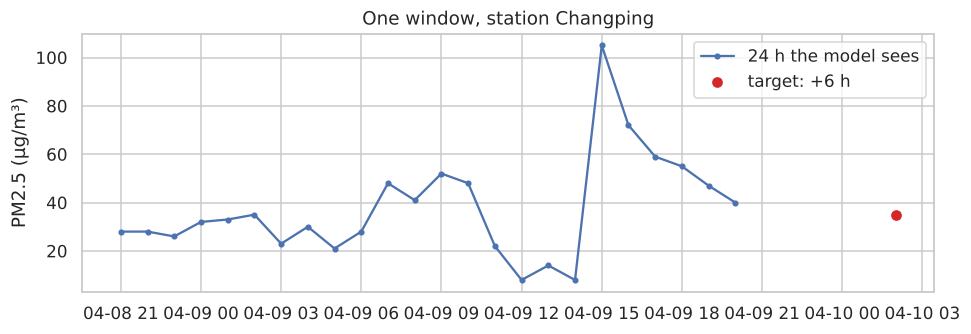

In [10]:
w, i = win["validation"], 5000
x = get_X(w, np.array([i]))[0]
pm_col = FEATURES.index(TARGET)
hours_in = pd.date_range(end=pd.Timestamp(w["time"][i]), periods=LOOKBACK, freq="h")
history = scalers["target"].inverse_transform(x[:, [pm_col]]).ravel()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(hours_in, history, marker=".", label="24 h the model sees")
ax.scatter(hours_in[-1] + pd.Timedelta(hours=HORIZON), w["y"][i], color="tab:red", zorder=3, label="target: +6 h")
ax.set(title=f"One window, station {w['station'][i]}", ylabel="PM2.5 (µg/m³)")
ax.legend(); plt.tight_layout(); plt.show()

**What we see.** About 77% of train hours and 89% of validation/test hours give a valid window. Train loses more because 2013–2014 had more sensor outages, and one missing input anywhere in the 24 hours drops the window (notebook 2 left long gaps empty on purpose). Windows whose target we filled ourselves are dropped too. The scaled PM2.5 inside the window turns back into µg/m³ with `inverse_transform`, which is exactly what we will do with the network's predictions.

## 4. Metrics
Every model in the project is scored with the same function, always in **µg/m³** (predictions are turned back from the scaled target first).

- **MAE** (main metric): average error in µg/m³; easy to explain.
- **RMSE**: punishes big misses more; matters for smog peaks.
- **R²**: share of the variation explained.
- **Macro-F1 on EPA bands**: we put the true and predicted values into the 6 EPA health bands and score them like a classifier. Macro means each band counts equally, so the rare "Hazardous" band matters as much as "Moderate". This covers the spec's classification metrics.

In [11]:
def to_band(values):
    return pd.cut(values, EPA_BANDS, labels=False, include_lowest=True)


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and R² in µg/m³, plus macro-F1 on the 6 EPA bands."""
    y_pred = np.clip(y_pred, 0, None)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "macro_F1_EPA": f1_score(to_band(y_true), to_band(y_pred), average="macro"),
    }


regression_metrics(np.array([10, 50, 200]), np.array([12, 40, 260]))   # quick check on 3 numbers

{'MAE': 24.0,
 'RMSE': 35.13782387494517,
 'R2': 0.8154152823920265,
 'macro_F1_EPA': 0.5}

## 5. Baseline 1: persistence
"PM2.5 in 6 hours = PM2.5 now." No training, no parameters. Air pollution changes slowly (autocorrelation 0.76 at 6 h, EDA §8), so this is a fair opponent: any network that cannot beat it is useless.

In [12]:
def persistence_baseline(w):
    """Predict that PM2.5 stays where it is now."""
    return w["pm25_now"]


results = []
for name in ("validation", "test"):
    m = regression_metrics(win[name]["y"], persistence_baseline(win[name]))
    results.append({"model": "Persistence", "split": name, **m})
pd.DataFrame(results).round(3)

,model,split,MAE,RMSE,R2,macro_F1_EPA
0,Persistence,validation,25.370,40.451,0.545,0.532
1,Persistence,test,38.395,65.821,0.562,0.506


## 6. Baseline 2: linear regression (Ridge)
A linear model cannot read a sequence, so we hand it the history as columns: **PM2.5 at each of the last 24 hours** (lags) plus **all 34 inputs at the last hour**. Ridge is linear regression with a small penalty that keeps weights from blowing up when columns are correlated (PM2.5 lags are).

It learns on train; the penalty strength `alpha` is picked on validation; test is touched once at the end.

In [13]:
def lag_features(w, lookback=LOOKBACK):
    """Flat table for the linear model: PM2.5 at each past hour + all inputs at the last hour."""
    pm_col = FEATURES.index(TARGET)
    lags = np.stack([w["values"][w["ends"] - k, pm_col] for k in range(lookback)], axis=1)
    return np.hstack([lags, w["values"][w["ends"]]])


def linear_baseline(X_train, y_train_scaled, alpha):
    """Fit Ridge regression on the scaled target."""
    return Ridge(alpha=alpha).fit(X_train, y_train_scaled)


def predict_ugm3(model, X):
    """Predict, then turn the scaled prediction back into µg/m³."""
    return scalers["target"].inverse_transform(model.predict(X).reshape(-1, 1)).ravel()


L = {name: lag_features(w) for name, w in win.items()}
print("linear model input:", L["train"].shape, "(windows, 24 lags + 34 inputs)")

search = []
for alpha in (0.1, 1, 10, 100, 1000):
    model = linear_baseline(L["train"], win["train"]["y_scaled"], alpha)
    search.append({"alpha": alpha, "val MAE": mean_absolute_error(win["validation"]["y"],
                                                                 np.clip(predict_ugm3(model, L["validation"]), 0, None))})
search = pd.DataFrame(search)
best_alpha = search.loc[search["val MAE"].idxmin(), "alpha"]
print("best alpha on validation:", best_alpha)
search.round(3)

linear model input: (242405, 58) (windows, 24 lags + 34 inputs)


best alpha on validation: 1000.0


,alpha,val MAE
0,0.1,25.349
1,1.0,25.349
2,10.0,25.348
3,100.0,25.341
4,1000.0,25.301


In [14]:
ridge = linear_baseline(L["train"], win["train"]["y_scaled"], best_alpha)
joblib.dump(ridge, MODELS_DIR / "baseline_ridge.joblib")

for name in ("validation", "test"):
    m = regression_metrics(win[name]["y"], predict_ugm3(ridge, L[name]))
    results.append({"model": f"Ridge (alpha={best_alpha:g})", "split": name, **m})
pd.DataFrame(results).round(3)

,model,split,MAE,RMSE,R2,macro_F1_EPA
0,Persistence,validation,25.370,40.451,0.545,0.532
1,Persistence,test,38.395,65.821,0.562,0.506
2,Ridge (alpha=1000),validation,25.301,38.806,0.581,0.416
3,Ridge (alpha=1000),test,38.598,63.547,0.591,0.450


## 7. Results and the bar to beat
All results go into one CSV log, `results/experiments.csv`. Every model in Checkpoint 3 and 4 adds its rows to the same file, so the final comparison table comes from one place (the spec asks for an experiment log).

In [15]:
def log_results(rows, path=RESULTS_PATH, notebook="milestone2_Features_Baselines"):
    """Append result rows to the shared experiment log (creates it the first time)."""
    path.parent.mkdir(exist_ok=True)
    new = pd.DataFrame(rows).assign(notebook=notebook, lookback=LOOKBACK, horizon=HORIZON,
                                    logged_at=pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"))
    if path.exists():
        old = pd.read_csv(path)
        old = old[~((old["notebook"] == notebook) & old["model"].isin(new["model"]))]   # re-runs replace
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(path, index=False)
    return new


log = log_results(results)
table = pd.DataFrame(results).pivot(index="model", columns="split", values=["MAE", "RMSE", "R2", "macro_F1_EPA"]).round(3)
table

MAE               RMSE                R2             \
split                 test validation    test validation   test validation   
model                                                                        
Persistence         38.395     25.370  65.821     40.451  0.562      0.545   
Ridge (alpha=1000)  38.598     25.301  63.547     38.806  0.591      0.581   

                   macro_F1_EPA             
split                      test validation  
model                                       
Persistence               0.506      0.532  
Ridge (alpha=1000)        0.450      0.416

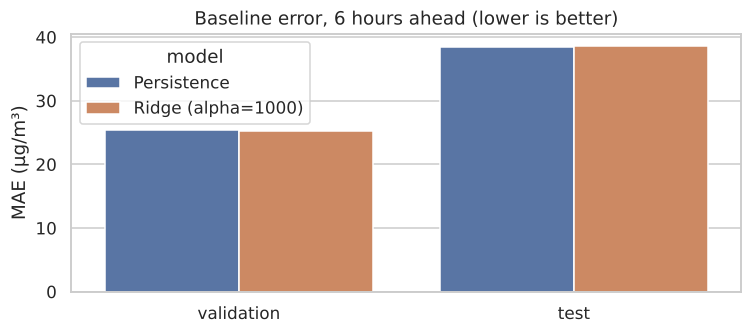

In [16]:
res = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.barplot(data=res, x="split", y="MAE", hue="model", ax=ax)
ax.set(title="Baseline error, 6 hours ahead (lower is better)", ylabel="MAE (µg/m³)", xlabel="")
plt.tight_layout(); plt.show()

In [17]:
w = win["test"]
err = pd.DataFrame({"true band": pd.Categorical.from_codes(to_band(w["y"]), EPA_LABELS),
                    "abs error": np.abs(predict_ugm3(ridge, L["test"]).clip(0) - w["y"])})
err.groupby("true band", observed=True)["abs error"].agg(["count", "mean"]).round(1)

,count,mean
true band,,
Good,8291,19.5
Moderate,9607,19.7
Sensitive groups,4358,21.3
Unhealthy,13702,30.8
Very unhealthy,6901,61.7
Hazardous,3364,146.5


**What we see.**
- **Ridge does not beat persistence on MAE** (about 25.3 vs 25.4 on validation, 38.6 vs 38.4 on test). It is better on RMSE and R², so it softens the big misses, but it blurs the EPA band edges (lower macro-F1). A straight-line model gets almost nothing out of 24 hours of history beyond "same as now". This is exactly the gap a recurrent network has to close.
- Errors grow with the pollution level: on test the mean miss is about 20 µg/m³ for "Good" hours and over 140 µg/m³ for "Hazardous" ones. The smog peaks are where an LSTM/GRU, which reads the whole 24-hour pattern, should gain most.
- Test errors are higher than validation for both baselines: test is autumn + winter (notebook 2 §5.3), so this gap is the season, not overfitting.

**The bar for Checkpoint 3.** SimpleRNN, LSTM and GRU must beat the **best baseline on each metric** in the table above (on test: MAE from persistence, RMSE and R² from Ridge). They will use exactly the same windows (`make_windows`, `get_X`), the saved `models/preprocessor.joblib`, the same `regression_metrics()`, and add their rows to `results/experiments.csv`.